# 01 — Analyse des politiques de référence



In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
from cyberdef.evaluate import bootstrap_ci
from cyberdef.env import NOISE_LEVELS

CSV = os.path.join(ROOT, "results", "baselines.csv")
df = pd.read_csv(CSV)
METRICS = ["return", "final_infected_frac", "peak_infected_frac", "availability",
           "healthy_unavailable_mean", "healthy_isolations", "healthy_restorations"]
NOISES = list(NOISE_LEVELS)           # low, medium, high
print("Fichier :", CSV, "| forme :", df.shape)
df.head()

Fichier : d:\DOCUMENT\rl_cyberdef\results\baselines.csv | forme : (600, 10)


,policy,noise,env_seed,return,final_infected_frac,peak_infected_frac,availability,healthy_unavailable_mean,healthy_isolations,healthy_restorations
0,random,low,100000,-303.2,0.333333,0.500000,0.631667,2.70,6,14
1,random,low,100001,-290.6,0.500000,0.500000,0.788333,2.10,7,12
2,random,low,100002,-331.0,0.750000,0.750000,0.611667,3.10,7,13
3,random,low,100003,-374.8,0.500000,0.583333,0.593333,2.78,4,9
4,random,low,100004,-208.2,0.083333,0.333333,0.598333,3.70,8,10


## 1. Contrôles de qualité des données

In [2]:
print("Colonnes attendues présentes :", set(["policy","noise","env_seed"] + METRICS) <= set(df.columns))
print("\nValeurs manquantes par colonne :")
print(df.isna().sum().to_string())
print("\nÉpisodes par (politique, bruit) :")
print(df.groupby(["policy", "noise"]).size().unstack())
print("\nGraines distinctes par groupe :", df.groupby(["policy","noise"]).env_seed.nunique().unique())
print("Plage des graines :", df.env_seed.min(), "->", df.env_seed.max(), "(disjointe de l'entraînement : >= 100000)")
assert df.isna().sum().sum() == 0
assert (df.groupby(["policy","noise"]).size() == 100).all()
assert df.availability.between(0, 1).all() and df.peak_infected_frac.between(0, 1).all()
print("\nContrôles OK")

Colonnes attendues présentes : True

Valeurs manquantes par colonne :
policy                      0
noise                       0
env_seed                    0
return                      0
final_infected_frac         0
peak_infected_frac          0
availability                0
healthy_unavailable_mean    0
healthy_isolations          0
healthy_restorations        0

Épisodes par (politique, bruit) :
noise             high  low  medium
policy                             
random             100  100     100
restore_if_alert   100  100     100

Graines distinctes par groupe : [100]
Plage des graines : 100000 -> 100099 (disjointe de l'entraînement : >= 100000)

Contrôles OK


## 2. Statistiques descriptives



In [3]:
rows = []
for (p, n), g in df.groupby(["policy", "noise"], sort=False):
    for m in METRICS:
        mu, lo, hi = bootstrap_ci(g[m])
        rows.append({"policy": p, "noise": n, "metric": m, "mean": mu, "sd": g[m].std(ddof=1),
                     "median": g[m].median(), "ci_lo": lo, "ci_hi": hi})
stats = pd.DataFrame(rows)
pd.set_option("display.width", 160)
stats.pivot_table(index=["policy","noise"], columns="metric", values="mean", sort=False)[METRICS].round(3)

metric                    return  final_infected_frac  peak_infected_frac  availability  healthy_unavailable_mean  healthy_isolations  healthy_restorations
policy           noise                                                                                                                                     
random           low    -249.460                0.257               0.408         0.636                     3.064                7.72                 11.83
                 medium -249.460                0.257               0.408         0.636                     3.064                7.72                 11.83
                 high   -249.460                0.257               0.408         0.636                     3.064                7.72                 11.83
restore_if_alert low     -10.852                0.000               0.092         0.980                     0.212                0.00                 10.62
                 medium  -25.078                0.007               0.112         0.959                     0.454                0.00                 22.68
                 high    -58.658                0.049               0.177         0.938                     0.652                0.00                 32.59

In [4]:
stats[stats.metric.isin(["return", "peak_infected_frac", "availability", "healthy_restorations"])].round(3)

,policy,noise,metric,mean,sd,median,ci_lo,ci_hi
0,random,low,return,-249.460,104.504,-265.650,-270.109,-228.273
2,random,low,peak_infected_frac,0.408,0.216,0.417,0.365,0.452
3,random,low,availability,0.636,0.077,0.629,0.621,0.651
6,random,low,healthy_restorations,11.830,3.877,12.000,11.060,12.600
7,restore_if_alert,low,return,-10.852,11.129,-9.600,-13.314,-9.376
9,restore_if_alert,low,peak_infected_frac,0.092,0.046,0.083,0.086,0.103
10,restore_if_alert,low,availability,0.980,0.006,0.980,0.979,0.981
13,restore_if_alert,low,healthy_restorations,10.620,2.940,10.000,10.030,11.190
14,random,medium,return,-249.460,104.504,-265.650,-270.109,-228.273
16,random,medium,peak_infected_frac,0.408,0.216,0.417,0.365,0.452


### Point d'attention : la ligne `random` est dupliquée entre niveaux
La politique aléatoire ignore les observations ; les alertes consomment le même nombre de tirages aléatoires quel que soit le bruit. Les trois niveaux donnent donc **le même épisode, graine par graine**. Vérification :

In [5]:
r = df[df.policy == "random"].pivot(index="env_seed", columns="noise", values=METRICS)
same = all(np.allclose(r[m][NOISES[0]], r[m][n]) for m in METRICS for n in NOISES[1:])
print("Résultats random identiques aux 3 niveaux :", same)

Résultats random identiques aux 3 niveaux : True


## 3. Graphiques comparatifs

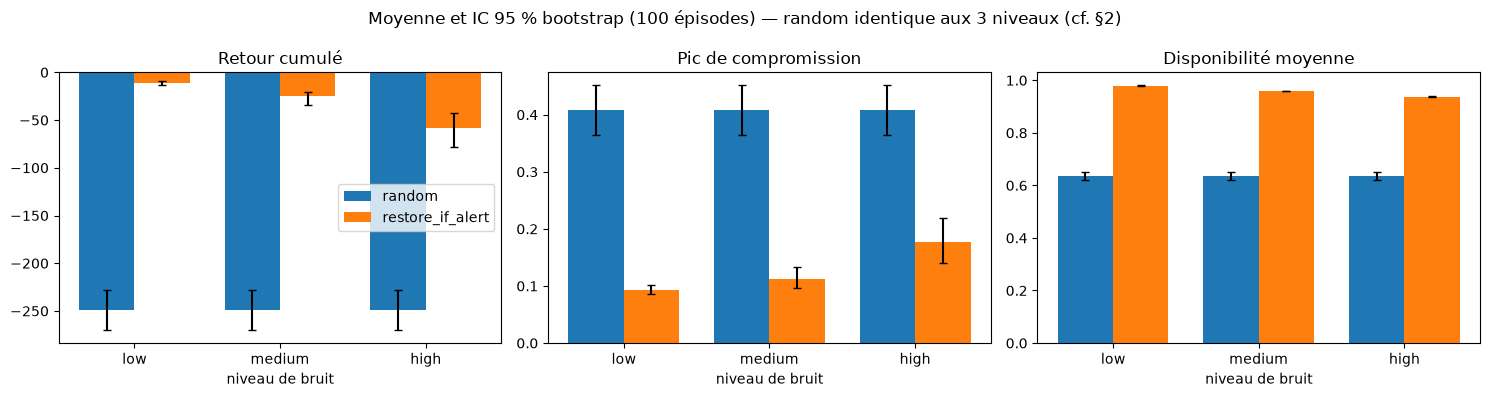

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, m, title in zip(axes, ["return", "peak_infected_frac", "availability"],
                        ["Retour cumulé", "Pic de compromission", "Disponibilité moyenne"]):
    w = 0.38
    for k, p in enumerate(["random", "restore_if_alert"]):
        mus, errs = [], [[], []]
        for n in NOISES:
            mu, lo, hi = bootstrap_ci(df[(df.policy == p) & (df.noise == n)][m])
            mus.append(mu); errs[0].append(mu - lo); errs[1].append(hi - mu)
        ax.bar(np.arange(3) + (k - 0.5) * w, mus, w, yerr=errs, capsize=3, label=p)
    ax.set_xticks(range(3)); ax.set_xticklabels(NOISES); ax.set_title(title); ax.set_xlabel("niveau de bruit")
axes[0].legend()
fig.suptitle("Moyenne et IC 95 % bootstrap (100 épisodes) — random identique aux 3 niveaux (cf. §2)")
plt.tight_layout(); plt.show()

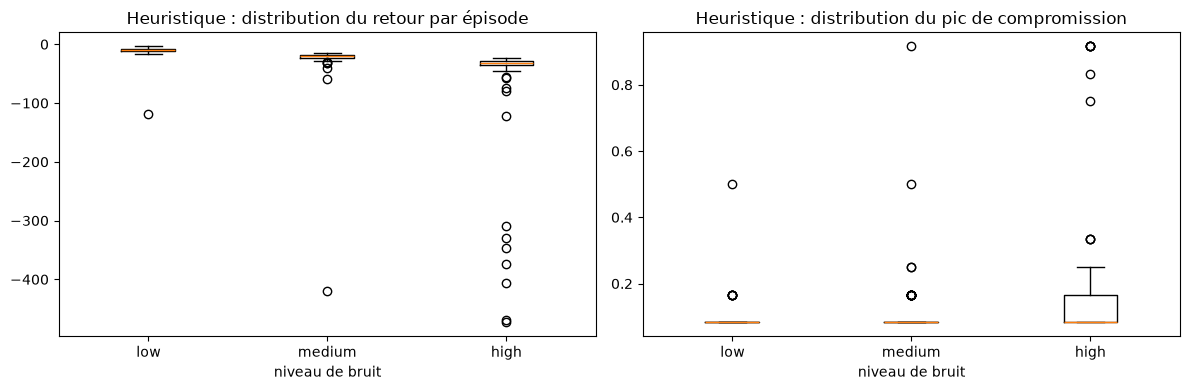

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
h = df[df.policy == "restore_if_alert"]
axes[0].boxplot([h[h.noise == n]["return"] for n in NOISES], tick_labels=NOISES)
axes[0].set_title("Heuristique : distribution du retour par épisode"); axes[0].set_xlabel("niveau de bruit")
axes[1].boxplot([h[h.noise == n]["peak_infected_frac"] for n in NOISES], tick_labels=NOISES)
axes[1].set_title("Heuristique : distribution du pic de compromission"); axes[1].set_xlabel("niveau de bruit")
plt.tight_layout(); plt.show()

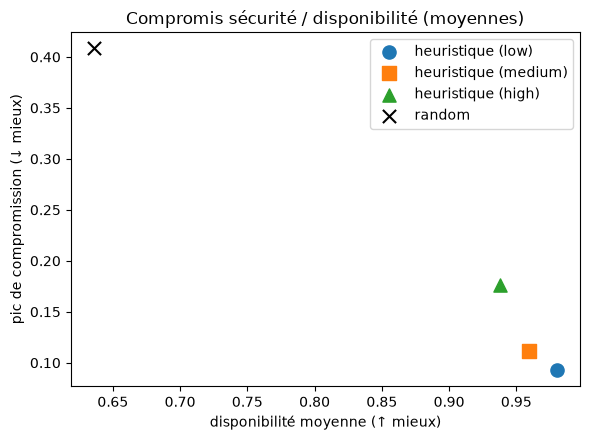

In [8]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for n, mk in zip(NOISES, ["o", "s", "^"]):
    g = h[h.noise == n]
    ax.scatter(g.availability.mean(), g.peak_infected_frac.mean(), marker=mk, s=90, label=f"heuristique ({n})")
g = df[df.policy == "random"].groupby("noise")[["availability", "peak_infected_frac"]].mean().iloc[0]
ax.scatter(g.availability, g.peak_infected_frac, marker="x", s=90, c="k", label="random")
ax.set_xlabel("disponibilité moyenne (↑ mieux)"); ax.set_ylabel("pic de compromission (↓ mieux)")
ax.set_title("Compromis sécurité / disponibilité (moyennes)"); ax.legend(); plt.tight_layout(); plt.show()

## 4. Différences appariées (même graine d'environnement)

In [9]:
out = []
for n in NOISES:
    a = df[(df.policy == "random") & (df.noise == n)].set_index("env_seed")
    b = df[(df.policy == "restore_if_alert") & (df.noise == n)].set_index("env_seed")
    for m in ["return", "peak_infected_frac", "availability"]:
        mu, lo, hi = bootstrap_ci((b[m] - a[m]).values)
        out.append({"bruit": n, "métrique": m, "heuristique − random": mu, "IC95 bas": lo, "IC95 haut": hi})
pd.DataFrame(out).round(3)

,bruit,métrique,heuristique − random,IC95 bas,IC95 haut
0,low,return,238.608,217.738,258.980
1,low,peak_infected_frac,-0.316,-0.358,-0.273
2,low,availability,0.344,0.329,0.359
3,medium,return,224.382,201.238,246.817
4,medium,peak_infected_frac,-0.297,-0.342,-0.250
5,medium,availability,0.323,0.308,0.339
6,high,return,190.802,164.819,215.277
7,high,peak_infected_frac,-0.232,-0.283,-0.178
8,high,availability,0.302,0.286,0.317


In [10]:
hp = h.pivot(index="env_seed", columns="noise")
out = []
for a, b in [("low", "medium"), ("medium", "high"), ("low", "high")]:
    for m in ["return", "peak_infected_frac", "availability", "healthy_restorations"]:
        mu, lo, hi = bootstrap_ci((hp[m][b] - hp[m][a]).values)
        out.append({"comparaison": f"{b} − {a}", "métrique": m, "diff": mu, "IC95 bas": lo, "IC95 haut": hi})
print("Effet du bruit sur l'heuristique (appariement par graine) :")
pd.DataFrame(out).round(3)

Effet du bruit sur l'heuristique (appariement par graine) :


,comparaison,métrique,diff,IC95 bas,IC95 haut
0,medium − low,return,-14.226,-23.106,-8.942
1,medium − low,peak_infected_frac,0.019,0.007,0.039
2,medium − low,availability,-0.021,-0.023,-0.020
3,medium − low,healthy_restorations,12.060,11.390,12.690
4,high − medium,return,-33.580,-53.438,-15.582
5,high − medium,peak_infected_frac,0.065,0.030,0.104
6,high − medium,availability,-0.021,-0.023,-0.020
7,high − medium,healthy_restorations,9.910,8.360,11.340
8,high − low,return,-47.806,-66.543,-31.789
9,high − low,peak_infected_frac,0.084,0.051,0.123


In [11]:
tail = h.assign(pic_ge_25pct=h.peak_infected_frac >= 0.25).groupby("noise").agg(
    part_episodes_pic_ge_25pct=("pic_ge_25pct", "mean"), retour_median=("return", "median"),
    retour_moyen=("return", "mean"), retour_min=("return", "min")).loc[NOISES]
tail.round(3)

,part_episodes_pic_ge_25pct,retour_median,retour_moyen,retour_min
noise,,,,
low,0.01,-9.6,-10.852,-118.0
medium,0.04,-20.0,-25.078,-420.0
high,0.18,-31.6,-58.658,-473.0
